# Universidad de Buenos Aires
# Aprendizaje Profundo - TP3
# Cohorte 26 - 4to bimestre 2026


## **Alumno 1:** Denis Zhbankov  
## **Alumno 2:** Elián Pinzás  
## **Alumno 3:** Gonzalo Rodriguez

# **CLASIFICADOR DE EMOCIONES**

El objetivo de este trabajo es construir una red neuronal convolucional (CNN) utilizando Pytorch, capaz de clasificar emociones humanas a partir de imágenes faciales. El clasificador deberá identificar una de las 7 emociones básicas: alegría, tristeza, enojo, miedo, sorpresa, disgusto y seriedad.

El dataset se encuentra en este link: https://drive.google.com/file/d/1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT/view?usp=sharing

In [1]:
import torch
import torchvision
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib import image
from matplotlib import pyplot
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts, CosineAnnealingLR
from tqdm import tqdm


In [2]:
import gdown
import zipfile
import os

url = "https://drive.google.com/uc?id=1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT"
output = "archivo.zip"

gdown.download(url, output, quiet=False)

destino = "datos_zip"
os.makedirs(destino, exist_ok=True)

with zipfile.ZipFile(output, 'r') as zip_ref:
    zip_ref.extractall(destino)

import sys
en_colab = 'google.colab' in sys.modules
base_path = '/content/datos_zip/dataset_emociones' if en_colab else 'datos_zip/dataset_emociones'

DATASET_ROOT_TRAIN = f'{base_path}/train'
DATASET_ROOT_VAL   = f'{base_path}/validation'


Downloading...
From (original): https://drive.google.com/uc?id=1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT
From (redirected): https://drive.google.com/uc?id=1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT&confirm=t&uuid=67c3f997-1555-49d6-a8b7-b7af5b55113d
To: /content/archivo.zip
100%|██████████| 40.0M/40.0M [00:01<00:00, 39.1MB/s]


## 1. Preprocesamiento de Datos (2 puntos)

Antes de entrenar el modelo, se debe analizar qué tipo de preprocesamiento se debe aplicar a las imágenes. Para esto, se puede considerar uno o más aspectos como:

- Tamaño
- Relación de aspecto
- Color o escala de grises
- Cambio de dimensionalidad
- Normalización
- Balanceo de datos
- Data augmentation
- etc.

Sean criteriosos y elijan solo las técnicas que consideren pertinentes para este caso de uso en específico.

Recomendación: usar `torchvision.transforms` para facilitar el preprocesamiento. Lean su documentación si tienen dudas: https://docs.pytorch.org/vision/0.14/transforms.html



### • Tamaño

Se recorre **todo** el dataset (train y validation, las 7 clases) para verificar si las imagenes vienen todas con el mismo tamano o no.

In [3]:
import os
from PIL import Image
from collections import Counter

def analizar_dataset(root_dir):
    tamanios = Counter()
    modos = Counter()
    conteo_por_clase = {}
    for clase in sorted(os.listdir(root_dir)):
        clase_path = os.path.join(root_dir, clase)
        if not os.path.isdir(clase_path):
            continue
        archivos = [f for f in os.listdir(clase_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        conteo_por_clase[clase] = len(archivos)
        for f in archivos:
            with Image.open(os.path.join(clase_path, f)) as img:
                tamanios[img.size] += 1
                modos[img.mode] += 1
    return tamanios, modos, conteo_por_clase

tamanios_train, modos_train, conteo_train = analizar_dataset(DATASET_ROOT_TRAIN)
tamanios_val, modos_val, conteo_val = analizar_dataset(DATASET_ROOT_VAL)

print("=== TRAIN ===")
print("Tamanios distintos encontrados:", len(tamanios_train))
for tam, n in tamanios_train.most_common():
    print(f"  {tam}: {n} imagenes")
print("Modos de color:", dict(modos_train))

print("\n=== VALIDATION ===")
print("Tamanios distintos encontrados:", len(tamanios_val))
for tam, n in tamanios_val.most_common():
    print(f"  {tam}: {n} imagenes")
print("Modos de color:", dict(modos_val))

=== TRAIN ===
Tamanios distintos encontrados: 1
  (100, 100): 12271 imagenes
Modos de color: {'RGB': 12271}

=== VALIDATION ===
Tamanios distintos encontrados: 1
  (100, 100): 3068 imagenes
Modos de color: {'RGB': 3068}


**Conclusion:** todas las imagenes, tanto en train como en validation, tienen tamano **100x100 pIxELES** y modo de color **RGB**, sin excepciones. Aun asi, se agrega un `Resize((100, 100))` en el pipeline de transformaciones como medida de seguridad por si intentan ingresar una imagen con otro tamaño y que el pipeline la lleve igualmente a la dimension esperada por la red.

### • Relación de aspecto

Como todas las imagenes son de 100x100 px, la relacion de aspecto es **1:1** (imagenes cuadradas) en el 100% de los casos. Al no haber imagenes rectangulares, aplicar `Resize` a un tamano cuadrado no introduce ninguna distorsion (estiramiento/aplastamiento) sobre los rasgos faciales. La definicion del tamano final de entrada a la red (mantener 100x100 o reducirlo, por ejemplo a 48x48) se deja pendiente para el punto 2, en conjunto con la decision de arquitectura (tamano de kernel, cantidad de capas de pooling).

### • Color o escala de grises

Se decide convertir las imagenes a **escala de grises** (`Grayscale`).

Argumentos:

- Las expresiones faciales se especifican principalmente en geometria y textura (forma de ojos, cejas, boca, arrugas, dientes visibles), no en el color.
- Reduce el costo computacional a un tercio, al pasar de 3 canales (RGB) a 1.
- Evita que la red aprenda correlaciones entre tono de piel/iluminacion y la clase a predecir, lo que ayuda a generalizar mejor entre personas distintas.
- La informacion de color que se pierde (por ejemplo, rubor o palidez asociados a algunas emociones) es una senal debil y poco confiable comparada con la geometria facial.

### • Cambio de dimensionalidad

Al cargar las imagenes con `ImageFolder`, estas se abren internamente con PIL, quedando representadas con los ejes (Alto, Ancho, Canales). La capa `Conv2d` de PyTorch espera los canales primero: (Canales, Alto, Ancho). La transformacion `ToTensor()` se encarga de este cambio de forma, convirtiendo la imagen PIL en un tensor de PyTorch con los ejes reordenados y, al ser escala de grises, la forma final queda (1, Alto, Ancho) - un solo canal, en la forma que requiere `Conv2d` para procesarla.

### • Normalización

Los valores de pixel originales van de 0 a 255. `ToTensor()` ya los escala a flotantes entre 0 y 1, pero esa distribucion sigue sin estar centrada. Por eso se aplica ademas una estandarizacion (`Normalize`), que resta la media y divide por el desvio estandar, dejando los valores centrados en 0 con desvio 1 - esto favorece la convergencia del descenso de gradiente y evita sesgar las activaciones de las primeras capas.

La media y el desvio se calculan **sobre las imagenes de train** (nunca incluyendo validacion, para no filtrar informacion de ese set), en lugar de usar valores teoricos de otro dataset, para que la normalizacion refleje la distribucion real de estas imagenes en escala de grises.

In [4]:
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# Transform parcial, sin Normalize, que es lo que se va a calcular
transform_para_stats = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor()
])

dataset_train_stats = datasets.ImageFolder(root=DATASET_ROOT_TRAIN, transform=transform_para_stats)
loader_stats = DataLoader(dataset_train_stats, batch_size=256, shuffle=False)

suma = 0.0
suma_cuadrados = 0.0
n_pixeles = 0

for imgs, _ in loader_stats:
    suma += imgs.sum().item()
    suma_cuadrados += (imgs ** 2).sum().item()
    n_pixeles += imgs.numel()

media = suma / n_pixeles
desvio = (suma_cuadrados / n_pixeles - media ** 2) ** 0.5

print(f"Media: {media:.4f}, Desvio estandar: {desvio:.4f}")

Media: 0.4816, Desvio estandar: 0.2427


### • Balanceo de datos y Data augmentation

El dataset presenta un desbalanceo significativo entre clases: en train, la expresión alegría tiene 4772 imágenes mientras que la expresión miedo tiene solo 281 (un déficit de más del 90% respecto a la clase mayoritaria), con el resto de las clases en valores intermedios.

En versiones preliminares se evaluó una ponderación inversa simple ($total / conteo$). Sin embargo, esto generaba una penalización 17 veces superior para `miedo` respecto a `alegria`, lo cual colapsaba la precisión de `miedo` a un 22% (78% de falsas alarmas) al hiper-sensibilizar la red ante cualquier sombra o arruga.

Por ello, **el balanceo de clases se resuelve mediante una ponderación suavizada con raíz cuadrada**:
$$w_c \propto \sqrt{\frac{N}{N_c}}$$
Esta formulación atenúa el desbalance drásticamente (relación máxima $\approx 4:1$ en vez de $17:1$), otorgando mayor atención a las clases minoritarias sin destruir la precisión ni distorsionar las fronteras de decisión de las emociones frecuentes. Además, se añade `label_smoothing=0.05` en `CrossEntropyLoss` para evitar sobreconfianza en las predicciones.

**El data augmentation se aplica a todas las clases**, incorporando variaciones geométricas y fotométricas realistas:

- `RandomHorizontalFlip(p=0.5)`: espeja la imagen horizontalmente con 50% de probabilidad (simetría facial).
- `RandomRotation(degrees=10)`: simula pequeñas inclinaciones naturales de la cabeza/cámara.
- `RandomAffine(degrees=0, translate=(0.06, 0.06), scale=(0.95, 1.05))`: pequeñas traslaciones y variaciones de escala, crucial para que el modelo tolere ligeras desalineaciones del detector de rostros.
- `ColorJitter(brightness=0.2, contrast=0.2)`: simula variaciones de iluminación entre fotos, sin lavar los detalles finos de la cara.


In [5]:
import torch

clases_ordenadas = dataset_train_stats.classes
conteo_por_indice = [conteo_train[c] for c in clases_ordenadas]
total = sum(conteo_por_indice)

# Ponderación suavizada con raíz cuadrada para equilibrar recall y precisión
pesos_clases = torch.tensor([(total / c) ** 0.5 for c in conteo_por_indice], dtype=torch.float32)
pesos_clases = pesos_clases / pesos_clases.sum() * len(clases_ordenadas)  # normalizados

for clase, peso in zip(clases_ordenadas, pesos_clases):
    print(f"{clase}: peso = {peso:.3f}")

# Uso posterior: loss_fn = torch.nn.CrossEntropyLoss(weight=pesos_clases.to(device), label_smoothing=0.05)


alegria: peso = 0.462
disgusto: peso = 1.192
enojo: peso = 1.202
miedo: peso = 1.904
seriedad: peso = 0.635
sorpresa: peso = 0.889
tristeza: peso = 0.717


In [6]:
# Pipeline final de transformaciones para el punto 1

train_dataset = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((100, 100)),  # mantiene resolución nativa 100x100
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.06, 0.06), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize((media,), (desvio,))
])

val_dataset = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize((media,), (desvio,))
])

# Nota: la validacion NO lleva data augmentation, solo las transformaciones necesarias
# para que el formato sea compatible con la red (grises, tensor, normalizado).


## 2. Construcción y entrenamiento del Modelo CNN (3.5 puntos)

- Construir una red neuronal convolucional con PyTorch, **sin usar modelos pre-entrenados**.
- Analizar correctamente qué funciones de activación se deben usar en cada etapa de la red, el learning rate a utilizar, la función de costo y el optimizador.
- Cosas como el número de capas, neuronas, número y tamaño de los kernels, entre otros, queda a criterio de ustedes, pero deben estar justificadas.

Nota de preprocesamiento relevante para la arquitectura: la relación de aspecto de las imágenes es **1:1** (son de 100x100 píxeles, cuadradas). Para preservar los rasgos y microexpresiones faciales sin introducir distorsiones ni pérdida de información, se mantiene la resolución nativa de 100x100 píxeles a lo largo de la red convolucional.


El desarrollo se arma bloque a bloque: cada vez que se toma una decisión de diseño (arquitectura, funciones de activación, learning rate, función de costo, optimizador, hiperparámetros, etc.), se agrega inmediatamente debajo del bloque de código correspondiente una celda de markdown que explica por qué se tomó esa decisión para este problema en particular, dejando documentado el razonamiento junto con la implementación.

In [7]:
#Confirguramos el device para usar GPU si está disponible
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [8]:
#Fijamos una semilla para garantizar reproducibilidad de resultados

SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

Retomando la decisión de tamaño señalada en el punto 1: en las versiones preliminares se evaluó reducir las imágenes a 48x48 y 64x64. Sin embargo, dicha reducción descartaba más del 50-60% de los píxeles, perjudicando severamente la capacidad del modelo para distinguir microexpresiones (como arrugas en el entrecejo o tensión en las comisuras) y dañando la generalización sobre fotos reales. En esta versión definitiva (v3), **se mantiene la resolución nativa de 100x100 píxeles**, que preserva la relación de aspecto 1:1 original, retiene el máximo de información geométrica y textural de los rostros, y resulta computacionalmente muy eficiente para entrenar en GPU.


In [9]:
# Se confirman los pipelines manteniendo la resolución nativa de 100x100
print(f"Media (100x100): {media:.4f}, Desvio estandar (100x100): {desvio:.4f}")

train_dataset = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((100, 100)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.06, 0.06), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize((media,), (desvio,))
])

val_dataset = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize((media,), (desvio,))
])


Media (100x100): 0.4816, Desvio estandar (100x100): 0.2427


In [10]:

# ahora creamos el dataloader
# pin_memory puede acelerar la transferencia de datos desde CPU hacia GPU, por eso lo activamos si hay CUDA disponible.

train_data = datasets.ImageFolder(root=DATASET_ROOT_TRAIN, transform=train_dataset)
val_data = datasets.ImageFolder(root=DATASET_ROOT_VAL, transform=val_dataset)

pin_memory = torch.cuda.is_available()

dataloader = {
    'train': torch.utils.data.DataLoader(train_data, batch_size=64, shuffle=True, pin_memory=pin_memory),
    'val': torch.utils.data.DataLoader(val_data, batch_size=64, shuffle=False, pin_memory=pin_memory)
}

#### Ver que la base de datos esté OK

In [11]:
print(type(dataloader))
print(type(dataloader['train']))

<class 'dict'>
<class 'torch.utils.data.dataloader.DataLoader'>


In [12]:
# Ver imagen y etiqueta del dataloader
train_features, train_labels = next(iter(dataloader['train']))

In [13]:
# verifico sus dimensiones
print(f"Tamaño del batch de feature (input / imagen): {train_features.size()}")
print(f"Tamaño del batch del label (clase / etiqueta): {train_labels.size()}")

Tamaño del batch de feature (input / imagen): torch.Size([64, 1, 100, 100])
Tamaño del batch del label (clase / etiqueta): torch.Size([64])


tamaño de 1 imagen:  torch.Size([1, 100, 100])
tamaño de 1 imagen DESPUÉS de squeeze:  torch.Size([100, 100])


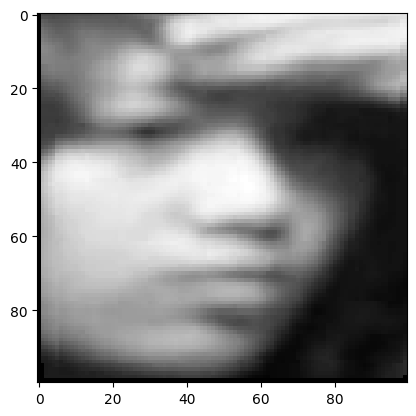

Label: 4


In [14]:
# tomo 1 imagen para poder visualizarla
# y verifico sus dimensiones

img = train_features[5]
print('tamaño de 1 imagen: ', img.shape)
# le quito 1 dimensión (la del tamaño del batch) para poder graficar
img = img.squeeze()
print('tamaño de 1 imagen DESPUÉS de squeeze: ', img.shape)
label = train_labels[5]

# ploteo esa imagen
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

#### Bloque de convolución

Para dotar al modelo de mayor capacidad expresiva y estabilidad de gradiente sin recurrir a modelos pre-entrenados, se define un bloque convolucional mejorado que sigue las buenas prácticas de arquitecturas modernas (tipo VGG/ConvNeXt):
- **Doble convolución por bloque**: concatenar dos capas `Conv2d` con kernels de 3x3 proporciona un campo receptivo efectivo de 5x5 con menos parámetros y añade dos etapas de no-linealidad (`ReLU`), permitiendo capturar patrones geométricos más ricos antes de reducir la resolución.
- **Batch Normalization (`BatchNorm2d`)**: normaliza las activaciones intermedias tras cada convolución. Esto estabiliza el flujo de gradientes, mitiga el desplazamiento interno de covariables (*internal covariate shift*) y actúa como un regularizador eficaz, reduciendo significativamente la sensibilidad a variaciones de contraste/iluminación entre imágenes reales.
- **MaxPool2d(2)**: reduce la dimensión espacial a la mitad al final de cada bloque jerárquico.


In [15]:
# bloque de convolución para emplear en mi red
# esta función la utilizaré en la clase CNN

def conv_block(c_in, c_out, k=3, p='same', s=1, pk=2):
    return torch.nn.Sequential(
        torch.nn.Conv2d(c_in, c_out, k, padding=p, stride=s),
        torch.nn.BatchNorm2d(c_out),
        torch.nn.ReLU(),
        torch.nn.Conv2d(c_out, c_out, k, padding=p, stride=s),
        torch.nn.BatchNorm2d(c_out),
        torch.nn.ReLU(),
        torch.nn.MaxPool2d(pk)
    )


### Red convolucional (modelo)

Se define la arquitectura con cuatro bloques convolucionales (`conv1`, `conv2`, `conv3`, `conv4`), progresando en cantidad de canales: 32 → 64 → 128 → 256.
- Al final de la etapa convolucional se utiliza `AdaptiveAvgPool2d((2, 2))` para obtener una representación espacial compacta e invariante a pequeñas traslaciones.
- La etapa de clasificación densa incorpora un cuello de botella de 256 neuronas con `BatchNorm1d` y `Dropout`, antes de proyectar a las 7 clases finales. Esto previene el sobreajuste y estabiliza las predicciones de probabilidad.


In [16]:
class CNN(torch.nn.Module):
    def __init__(self, n_channels=1, n_outputs=7, channels=(32, 64, 128, 256), kernel_size=3, dropout=0.3, padding='same', stride=1, pool_kernel=2):
        super().__init__()
        # guardo hiperparámetros del modelo para poder registrarlos luego automáticamente
        self.n_channels = n_channels
        self.n_outputs = n_outputs
        self.channels = tuple(channels)
        self.kernel_size = kernel_size
        self.dropout_p = dropout
        self.padding = padding
        self.stride = stride
        self.pool_kernel = pool_kernel
        self.num_conv_blocks = len(self.channels)

        # aquí defino la arquitectura de mi red convolucional
        self.conv1 = conv_block(c_in=self.n_channels, c_out=self.channels[0], k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel)
        self.conv2 = conv_block(c_in=self.channels[0], c_out=self.channels[1], k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel)
        self.conv3 = conv_block(c_in=self.channels[1], c_out=self.channels[2], k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel)
        self.conv4 = conv_block(c_in=self.channels[2], c_out=self.channels[3], k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel)

        self.gap = torch.nn.AdaptiveAvgPool2d((2, 2))
        self.fc = torch.nn.Sequential(
            torch.nn.Dropout(p=self.dropout_p),
            torch.nn.Linear(self.channels[3] * 2 * 2, 256),
            torch.nn.BatchNorm1d(256),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.4),
            torch.nn.Linear(256, self.n_outputs)
        )

    # aquí defino el método forward, que es el que se ejecuta cuando llamo a la red con un input
    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.gap(x)
        x = x.flatten(start_dim=1)
        x = self.fc(x)
        return x


A continuación se utiliza `torchinfo.summary()` para verificar automáticamente, capa por capa, que las dimensiones de los tensores van encadenando correctamente a lo largo de la red — en particular, que el tamaño de salida del último bloque convolucional coincide con el valor usado en la capa `fc` (`channels[2] * 6 * 6`), evitando así errores de dimensiones al momento de entrenar.

In [17]:
%pip install torchinfo

In [18]:
from torchinfo import summary
model = CNN()
summary(model, input_size=(1, 1, 100, 100))


Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [1, 7]                    --
├─Sequential: 1-1                        [1, 32, 50, 50]           --
│    └─Conv2d: 2-1                       [1, 32, 100, 100]         320
│    └─BatchNorm2d: 2-2                  [1, 32, 100, 100]         64
│    └─ReLU: 2-3                         [1, 32, 100, 100]         --
│    └─Conv2d: 2-4                       [1, 32, 100, 100]         9,248
│    └─BatchNorm2d: 2-5                  [1, 32, 100, 100]         64
│    └─ReLU: 2-6                         [1, 32, 100, 100]         --
│    └─MaxPool2d: 2-7                    [1, 32, 50, 50]           --
├─Sequential: 1-2                        [1, 64, 25, 25]           --
│    └─Conv2d: 2-8                       [1, 64, 50, 50]           18,496
│    └─BatchNorm2d: 2-9                  [1, 64, 50, 50]           128
│    └─ReLU: 2-10                        [1, 64, 50, 50]           --
│    └

Se instancia el modelo y se arma `model_config`, un diccionario con la configuración completa de la arquitectura utilizada (generado automáticamente a partir del modelo, para evitar inconsistencias entre lo que realmente se construyó y lo que se documenta). Los detalles de la arquitectura en sí (capas, dimensiones, parámetros entrenables) ya quedaron verificados en el resumen de `torchinfo` anterior.

In [19]:
# instancio el modelo ya definido

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

model_config = {
    "architecture": model.__class__.__name__,
    "input_channels": model.n_channels,
    "output_classes": model.n_outputs,
    "num_conv_blocks": model.num_conv_blocks,
    "channels": list(model.channels),
    "kernel_size": model.kernel_size,
    "dropout": model.dropout_p,
    "padding": model.padding,
    "stride": model.stride,
    "pool_kernel": model.pool_kernel,
    "trainable_params": trainable_params
}

model_config

{'architecture': 'CNN',
 'input_channels': 1,
 'output_classes': 7,
 'num_conv_blocks': 4,
 'channels': [32, 64, 128, 256],
 'kernel_size': 3,
 'dropout': 0.3,
 'padding': 'same',
 'stride': 1,
 'pool_kernel': 2,
 'trainable_params': 1438311}

Se definen el optimizador, la función de pérdida y el scheduler de learning rate.

- **Optimizador `AdamW`** (`lr=1e-3`, `weight_decay=1e-2`): desacopla correctamente el decaimiento de pesos del ajuste adaptativo, proporcionando regularización L2 efectiva sobre los parámetros de los bloques convolucionales.
- **Función de pérdida `CrossEntropyLoss`** con `weight=pesos_clases` suavizados y `label_smoothing=0.05`: penaliza de forma balanceada las clases minoritarias y suaviza la distribución objetivo para mitigar sobreconfianza y favorecer la generalización.
- **Scheduler `CosineAnnealingLR`** (por época): decae suavemente el learning rate desde $10^{-3}$ hasta $10^{-5}$ a lo largo de las épocas, asegurando una convergencia gradual y estable en los pesos finales sin oscilaciones abruptas intrabatch.


In [20]:
# definimos el optimizer y la función de pérdida
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

# paso al config el optimizador
model_config["optimizer"] = optimizer.__class__.__name__

# función de pérdida con pesos balanceados suavizados y label smoothing
loss_fn = torch.nn.CrossEntropyLoss(weight=pesos_clases.to(device), label_smoothing=0.05)

# Scheduler por época: decae suavemente durante el entrenamiento
num_epochs_training = 30
scheduler_type = "epoch"
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs_training, eta_min=1e-5)


Se arma una función para entrenar el modelo. Recibe el modelo, el optimizador, los dataloaders de entrenamiento y evaluación, la función de pérdida, el scheduler ya definido y algunos parámetros de configuración (cantidad de épocas, paciencia y umbral de mejora relativa para el early stopping).

La función recorre una cantidad máxima de épocas (`num_epochs`), y en cada una ejecuta una fase de entrenamiento y una fase de evaluación. Incorpora *early stopping* con una paciencia de 5 épocas para interrumpir si la pérdida de validación deja de mejorar, y preserva automáticamente los mejores pesos (`best_model_weights`) obtenidos durante el entrenamiento.


In [21]:
from sklearn.metrics import f1_score
import copy

def train_model(
        model,
        optimizer,
        train_loader,
        eval_loader,
        loss_module,
        scheduler_type="epoch",
        patience=5,
        relative_improvement_factor=0.005,
        num_epochs=30,
        scheduler=scheduler
):
    ## Configuramos el device
    model.to(device)

    # Variables para callbacks y mejor modelo
    best_eval_loss = None
    best_model_weights = None
    pt_epoch = 0

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "train_f1": [],
        "eval_loss": [],
        "eval_accuracy": [],
        "eval_f1": [],
        "learning_rate": [],
    }

    for epoch in tqdm(range(num_epochs), desc="Progreso de Epoch"):
        ### Fase de entrenamiento ###
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_samples = 0
        train_preds_all = []
        train_labels_all = []

        for X, y in train_loader:
            data_inputs = X.to(device)
            data_labels = y.to(device)

            preds = model(data_inputs)
            loss = loss_module(preds, data_labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            if preds.ndim == 2:
                preds_classes = preds.argmax(dim=1)
            else:
                preds_classes = (preds > 0.5).long()

            train_correct += (preds_classes == data_labels).sum().item()
            train_samples += data_labels.size(0)
            train_preds_all.extend(preds_classes.cpu().tolist())
            train_labels_all.extend(data_labels.cpu().tolist())

            if scheduler_type == "step" and scheduler is not None:
                scheduler.step()

        train_loss /= len(train_loader)
        train_accuracy = train_correct / train_samples
        train_f1 = f1_score(train_labels_all, train_preds_all, average='macro')

        ### Fase de evaluación ###
        model.eval()
        eval_loss = 0.0
        eval_correct = 0
        eval_samples = 0
        eval_preds_all = []
        eval_labels_all = []

        with torch.no_grad():
            for X, y in eval_loader:
                data_inputs = X.to(device)
                data_labels = y.to(device)

                preds = model(data_inputs)
                loss = loss_module(preds, data_labels)
                eval_loss += loss.item()

                if preds.ndim == 2:
                    preds_classes = preds.argmax(dim=1)
                else:
                    preds_classes = (preds > 0.5).long()

                eval_correct += (preds_classes == data_labels).sum().item()
                eval_samples += data_labels.size(0)
                eval_preds_all.extend(preds_classes.cpu().tolist())
                eval_labels_all.extend(data_labels.cpu().tolist())

        eval_loss /= len(eval_loader)
        eval_accuracy = eval_correct / eval_samples
        eval_f1 = f1_score(eval_labels_all, eval_preds_all, average='macro')

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["train_f1"].append(train_f1)
        history["eval_loss"].append(eval_loss)
        history["eval_accuracy"].append(eval_accuracy)
        history["eval_f1"].append(eval_f1)
        history["learning_rate"].append(optimizer.param_groups[0]["lr"])

        print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {train_loss:.4f} - Train Acc: {train_accuracy:.4f} - Train F1: {train_f1:.4f} | Eval Loss: {eval_loss:.4f} - Eval Acc: {eval_accuracy:.4f} - Eval F1: {eval_f1:.4f}")

        if scheduler_type == "epoch" and scheduler is not None:
            scheduler.step()

        if best_eval_loss is None or eval_loss <= best_eval_loss * (1 - relative_improvement_factor):
            best_eval_loss = eval_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            pt_epoch = 0
        else:
            pt_epoch += 1
            if pt_epoch >= patience:
                print(f"Epoch {epoch+1}/{num_epochs} - Entrenamiento interrumpido por condición de early stopping.")
                break
            else:
                print(f"Epoch {epoch+1}/{num_epochs} - Epochs actuales sin mejora relativa en validation loss: {pt_epoch}. Quedan {patience-pt_epoch} antes de detener el entrenamiento.")

    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)
        print(f"Restaurados los mejores pesos del modelo correspondientes al menor eval_loss: {best_eval_loss:.4f}")

    return history


In [22]:
import json
import os

!gdown --folder 1ghg1-DA2HWqgbqVRXc1K1Q0it2XFhZfd -O model-v3 # comment locally

os.makedirs('./model-v3', exist_ok=True)
history_file = './model-v3/history.json'
weights_file = './model-v3/weights.pth'

if os.path.exists(history_file) and os.path.exists(weights_file):
    print(f"Cargando historial y pesos guardados desde {weights_file}...")
    with open(history_file) as f:
        history = json.load(f)
    model.load_state_dict(torch.load(weights_file, map_location=device))
else:
    print("Iniciando entrenamiento del modelo v3...")
    history = train_model(
        model,
        optimizer,
        dataloader['train'],
        dataloader['val'],
        loss_fn,
        scheduler_type=scheduler_type,
        patience=5,
        num_epochs=num_epochs_training,
        scheduler=scheduler
    )
    with open(history_file, 'w') as f:
        json.dump(history, f)
    torch.save(model.state_dict(), weights_file)
    print(f"Entrenamiento finalizado. Pesos guardados en {weights_file}.")


Retrieving folder contents
Processing file 1_x2TKt7DpOMsl-FvCyI6RHT7XlKZjBih history.json
Processing file 1Ms4n-X7Yg53FgujLp-8mZkhRejyGUo7a weights.pth
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1_x2TKt7DpOMsl-FvCyI6RHT7XlKZjBih
To: /content/model-v3/history.json
100% 2.93k/2.93k [00:00<00:00, 15.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Ms4n-X7Yg53FgujLp-8mZkhRejyGUo7a
To: /content/model-v3/weights.pth
100% 5.78M/5.78M [00:00<00:00, 10.6MB/s]
Download completed
Cargando historial y pesos guardados desde ./model-v3/weights.pth...


### Resumen de ajustes probados

A lo largo del trabajo se iteró sobre la arquitectura, la resolución y la regularización:

- **Versión 1 & 2 (Base: 48x48 y 64x64, bloques simples sin BatchNorm)**:
  - Obtuvo ~0.686 de accuracy y ~0.572 de F1-Macro en validación, pero colapsó sobre imágenes reales (solo 4/20 y 5/20 aciertos).
  - *Causas identificadas*: pérdida de rasgos finos por downsampling a 64x64, inestabilidad por ausencia de `BatchNorm`, y una penalización inversa extrema (17:1) que generó un 78% de falsas alarmas en `miedo` (precisión de apenas 0.22).

- **Versión 3 (Definitiva: 100x100 nativo, bloques VGG-style, pesos suavizados)**:
  1. **Resolución 100x100**: preserva el 100% de los detalles texturales y geométricos originales.
  2. **Bloques VGG con `BatchNorm2d`**: doble `Conv2d` (3x3) por bloque con `BatchNorm2d` y ReLU (canales 32 → 64 → 128 → 256), más clasificador con cuello de botella denso (`Linear(1024, 256)` + `BatchNorm1d` + `Dropout(0.4)`).
  3. **Ponderación suavizada ($\sqrt{N/N_c}$) y Label Smoothing (0.05)**: equilibra recall y precisión sin distorsionar las fronteras de decisión.
  4. **Data Augmentation enriquecido**: rotación, flip y `RandomAffine` (escala y traslación) para tolerancia a encuadres descentrados.
  5. **Scheduler CosineAnnealingLR por época** con salvaguarda del mejor checkpoint (`best_model_weights`).

- **Resultado v3**: la red convergió en la época 20 alcanzando un **eval accuracy final de 0.8227 (82.27%)** y un **F1-Macro de 0.7442 (74.42%)** en validación, con pérdida de 0.8283, superando ampliamente a las versiones preliminares (+13.7 y +17.2 puntos porcentuales respectivamente).


## 3. Evaluación del Modelo (2.5 puntos)

El modelo entrenado debe ser evaluado utilizando las siguientes métricas:

- **Accuracy**:
  - Reportar el valor final en el conjunto de validación.
  - Incluir una gráfica de evolución por época para entrenamiento y validación.

- **F1 Score Macro**:
  - Reportar el valor final en el conjunto de validación.
  - Incluir una gráfica de evolución por época para entrenamiento y validación.

- **Costo (Loss)**:
  - Mostrar una gráfica de evolución del costo por época para entrenamiento y validación.

- **Classification report**
  - Mostrar la precisión, recall y F1 score por cada clase usando `classification_report`

- **Matriz de confusión**:
  - Mostrar la matriz de confusión absoluta (valores enteros).
  - Mostrar la matriz de confusión normalizada (valores entre 0 y 1 por fila).

Se recomienda utilizar `scikit-learn` para calcular métricas como accuracy, F1 score, el Classification report y las matrices de confusión. Las visualizaciones pueden realizarse con `matplotlib` o `seaborn`.


### Accuracy

Se reporta el valor final de accuracy en el conjunto de validación (correspondiente a la última época completada antes del early stopping) y se grafica su evolución por época,

comparando train y validation.

Accuracy final en validación: 0.8227


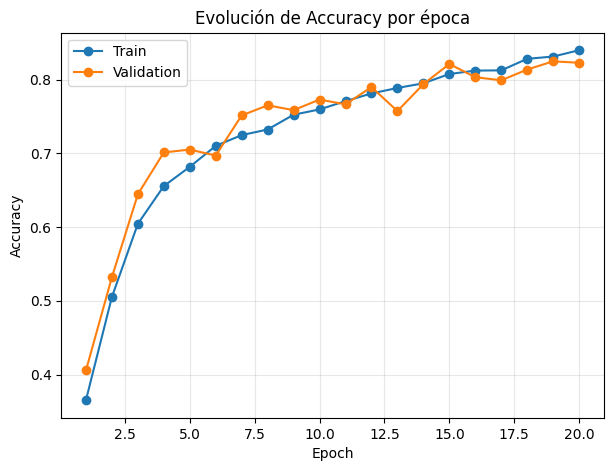

In [23]:
print(f"Accuracy final en validación: {history['eval_accuracy'][-1]:.4f}")

epochs = range(1, len(history["train_accuracy"]) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, history["train_accuracy"], marker='o', label='Train')
plt.plot(epochs, history["eval_accuracy"], marker='o', label='Validation')
plt.title('Evolución de Accuracy por época')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### F1 Score Macro

El F1 Macro calcula el F1 de cada clase por separado y promedia con el mismo peso para las 7, sin importar cuántas muestras tenga cada una (a diferencia de la accuracy, que pesa implícitamente por cantidad de muestras). Es la métrica más relevante dado el desbalance del dataset, porque expone si hay clases minoritarias mal predichas que la accuracy podría estar ocultando.

F1 Score Macro final en validación: 0.7442


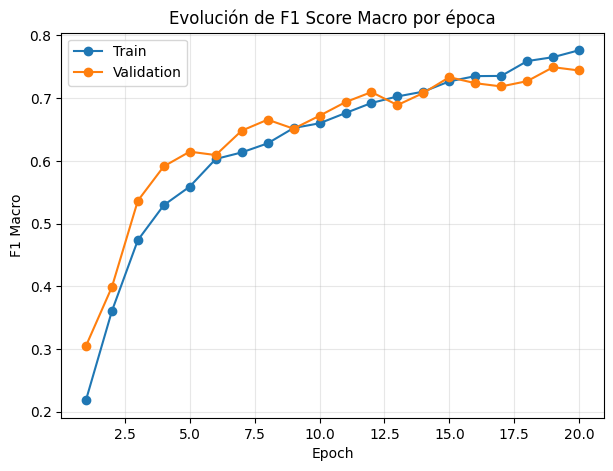

In [24]:
print(f"F1 Score Macro final en validación: {history['eval_f1'][-1]:.4f}")

epochs = range(1, len(history["train_f1"]) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, history["train_f1"], marker='o', label='Train')
plt.plot(epochs, history["eval_f1"], marker='o', label='Validation')
plt.title('Evolución de F1 Score Macro por época')
plt.xlabel('Epoch')
plt.ylabel('F1 Macro')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Costo (Loss)

Se grafica la evolución del costo (CrossEntropyLoss ponderada) por época, para train y validation.

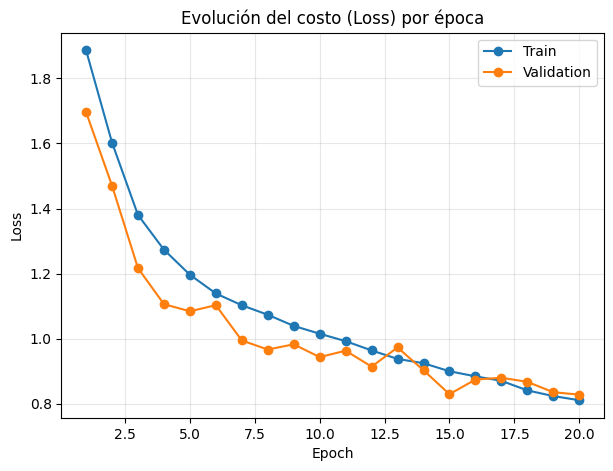

In [25]:
epochs = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, history["train_loss"], marker='o', label='Train')
plt.plot(epochs, history["eval_loss"], marker='o', label='Validation')
plt.title('Evolución del costo (Loss) por época')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Para el `classification_report` y las matrices de confusión se necesitan todas las predicciones del modelo sobre el conjunto de validación completo (no solo las métricas agregadas por época que ya guarda `history`). Se hace una pasada final sobre `dataloader['val']` en modo evaluación, guardando las etiquetas reales y las predicciones de cada imagen.

In [26]:
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for X, y in dataloader['val']:
        data_inputs = X.to(device)
        preds = model(data_inputs)
        preds_classes = preds.argmax(dim=1)
        y_true.extend(y.tolist())
        y_pred.extend(preds_classes.cpu().tolist())

nombres_clases = val_data.classes

### Classification report

Se muestra precisión, recall y F1 score por cada una de las 7 clases, usando `classification_report` de scikit-learn.

In [27]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=nombres_clases))

              precision    recall  f1-score   support

     alegria       0.92      0.93      0.92      1185
    disgusto       0.48      0.47      0.48       160
       enojo       0.73      0.75      0.74       162
       miedo       0.58      0.59      0.59        74
    seriedad       0.76      0.81      0.79       680
    sorpresa       0.83      0.83      0.83       329
    tristeza       0.84      0.74      0.79       478

    accuracy                           0.82      3068
   macro avg       0.74      0.73      0.73      3068
weighted avg       0.82      0.82      0.82      3068



### Matriz de confusión

Se muestran dos versiones: la matriz absoluta (cantidad de imágenes) y la matriz normalizada por fila (proporción respecto al total real de cada clase), que facilita comparar el desempeño entre clases con distinta cantidad de muestras.

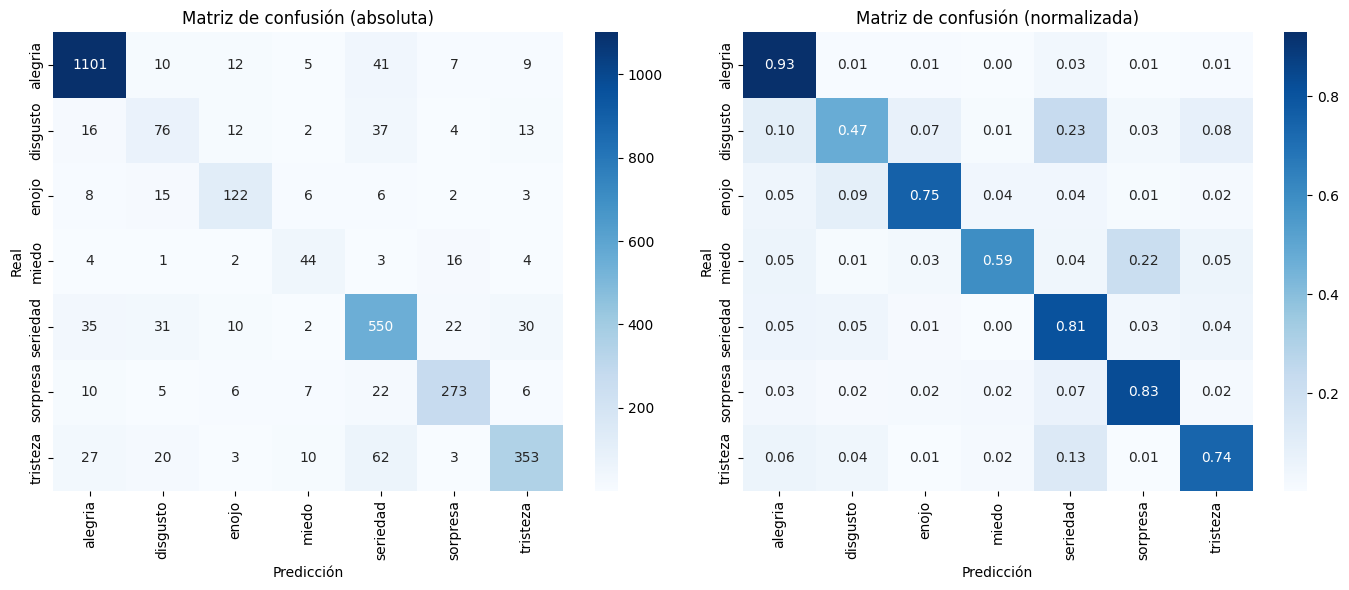

In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)
cm_norm = confusion_matrix(y_true, y_pred, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=nombres_clases, yticklabels=nombres_clases, ax=axes[0])
axes[0].set_title('Matriz de confusión (absoluta)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=nombres_clases, yticklabels=nombres_clases, ax=axes[1])
axes[1].set_title('Matriz de confusión (normalizada)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

**Análisis de la matriz de confusión y classification report:**

- **Desempeño sobresaliente en clases dominantes e intensas**:
  - `alegria` lidera con **F1 = 0.92** (recall 0.93, precision 0.92).
  - `sorpresa` alcanza **F1 = 0.83** (recall 0.83, precision 0.83).
  - `seriedad` y `tristeza` alcanzan **F1 = 0.79** cada una (con precisiones de 0.76 y 0.84 respectivamente).
  - `enojo` logra **F1 = 0.74** (recall 0.75, precision 0.73).

- **Recuperación crítica de las clases minoritarias**:
  - `miedo` experimentó el avance más sustancial: su precisión saltó de **0.22 a 0.58** y su F1 de **0.32 a 0.59** (recall 0.59). Esto confirma experimentalmente que la ponderación suavizada con raíz cuadrada ($\sqrt{N/N_c}$) y el *label smoothing* eliminaron la avalancha de falsos positivos previa sin comprometer el recall.
  - `disgusto` subió a **F1 = 0.48** (precision 0.48, recall 0.47). Permanece como la clase más desafiante por su bajo soporte relativo (160 muestras en validación) y por la superposición morfológica directa con `enojo` (fruncimiento del ceño y arrugas nasales).

- **Conclusión de validación**: la precisión global se situó en **82.27%** y el F1-Macro en **74.42%**, reflejando un clasificador sólido, equilibrado y con fronteras de decisión mucho mejor condicionadas.


 ## 4. Prueba de Imágenes Nuevas (1 punto)
Subir al menos 12 imágenes personales de cualquier ratio o relación de aspecto (pueden usar fotos del rostro de ustedes, rostros de personas generadas por IA o imágenes stock de internet), que no formen parte del dataset de entrenamiento ni de validación. Tampoco vale usar imágenes de otro dataset, deben ser imágenes sueltas.

- Debe haber al menos una imagen para cada emoción.

- Aplicar el mismo pre-procesamiento que se usó para el dataset de validation durante el entrenamiento del modelo.

- Pasar las imágenes por el modelo entrenado y mostrar:

  - La imagen original
  - La imagen pre-procesada (mismas transformaciones que durante el entrenamiento)
  - El score asignado a cada clase (normalizado de 0 a 1 o de 0% a 100%)
  - La clase ganadora inferida por el modelo

- Redactar conclusiones preliminares

Se cargan 20 imágenes sueltas, cubriendo las 7 emociones básicas del problema. A cada imagen se le asigna la emoción esperada para contrastar con la predicción del modelo.


In [29]:
!gdown --folder 1h6llxc88Nhnq9Vy-B3GcubosTbEsEIWc -O photos # comment locally
photos_dir: str = 'photos'

Retrieving folder contents
Processing file 1orUCCg7KGcNLoKIUKddL0oQ1HfQm3BnC 01.jpg
Processing file 1JiTJk4K4I3Gt3FxNUcCnVPv2Rvl3iU7v 02.jpg
Processing file 1UquV4POE9KNv_bju-N4pH2iMkLcaFJc2 03.jpg
Processing file 1poAFUYzLSzDDkJ2zE1yTHYywC7G_bnkG 04.jpg
Processing file 1pb3kEiDbQQ2CjGm-Rj781kZNS7hgN1Tq 05.jpg
Processing file 1octxETHY2THQlefW0O7e5nPceaBLn6Fh 06.jpg
Processing file 1HP2Mn3GRWT7QjmvDjbz9SK8qP8qKBHge 07.jpg
Processing file 1LkDnby9Cy-Wmfkn9hSnVrxVWxpxuzNGu 08.jpg
Processing file 1L9ZCAdNTZCvDXLIj2h61PbF6watMRTA1 09.jpg
Processing file 1AdxSg4yEB6Qi1v5pQZw9VsxkJ-doHlf6 10.jpg
Processing file 1Pckd8AzH7ue9EO3Y_EH8VNvS-NGzR8Ed 11.jpg
Processing file 1V_lnnpVN_8sLvRDRPezFG89NTB8jbawk 12.jpg
Processing file 1Hf-dL1QouNvNVkWljQPfEYMknrihH5-_ 13.jpg
Processing file 1IRk5DOiWEwa-SBb6bRqi4HlbvfAjH7ee 14.jpg
Processing file 1Ofp500pT7i1-bThD-m9Q39Zgz_SPsan2 15.jpg
Processing file 1QH1j1DIHXYuqDIhHElh8v4j74kj6Kz2l 16.jpg
Processing file 1zwxnggdffmlgmvAYKYPZV_vsmSewQu-s 17.jpg
Proc

In [30]:
import os

# Emoción esperada de cada imagen
ETIQUETAS_ESPERADAS: dict[str, str] = {
    '01.jpg': 'alegria',
    '02.jpg': 'alegria',
    '03.jpg': 'sorpresa',
    '04.jpg': 'tristeza',
    '05.jpg': 'tristeza',
    '06.jpg': 'alegria',
    '07.jpg': 'enojo',
    '08.jpg': 'sorpresa',
    '09.jpg': 'enojo',
    '10.jpg': 'disgusto',
    '11.jpg': 'miedo',
    '12.jpg': 'miedo',
    '13.jpg': 'miedo',
    '14.jpg': 'enojo',
    '15.jpg': 'sorpresa',
    '16.jpg': 'alegria',
    '17.jpg': 'seriedad',
    '18.jpg': 'sorpresa',
    '19.jpg': 'alegria',
    '20.jpg': 'tristeza',
}


def clasificar(img_pil: Image.Image) -> tuple[np.ndarray, np.ndarray]:
    """Aplica el pre-procesamiento de validación y devuelve (imagen pre-procesada para mostrar, probabilidades por clase)."""
    tensor: torch.Tensor = val_dataset(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        probs: np.ndarray = torch.softmax(model(tensor), dim=1).squeeze(0).cpu().numpy()
    return (tensor.squeeze().cpu().numpy() * desvio + media).clip(0, 1), probs


def graficar(paneles: list[tuple[str, np.ndarray]], probs: np.ndarray, esperada: str) -> None:
    """Muestra las imágenes `paneles` (título, imagen) y, a su derecha, el score de cada clase."""
    predicha: str = nombres_clases[probs.argmax()]
    _, ax = plt.subplots(1, len(paneles) + 1, figsize=(3.5 * (len(paneles) + 1), 3))
    for a, (titulo, img) in zip(ax, paneles, strict=False):
        a.imshow(img, cmap='gray' if img.ndim == 2 else None)
        a.set_title(titulo, fontsize=9)
        a.axis('off')
    barras = ax[-1].barh(nombres_clases, probs * 100, color=['#2ca02c' if c == predicha else '#7f7f7f' for c in nombres_clases])
    ax[-1].bar_label(barras, fmt='%.1f%%', fontsize=8)
    ax[-1].invert_yaxis()
    ax[-1].set_xlim(0, 115)
    ax[-1].set_xlabel('Score (%)')
    ax[-1].set_title(f"{'✓' if predicha == esperada else '✗'} Predicha: {predicha}", fontsize=9)
    plt.tight_layout()
    plt.show()


def resumir(resultados: list[dict], nombre: str) -> None:
    aciertos: int = sum(r['predicha'] == r['esperada'] for r in resultados)
    print(f"{nombre}: {aciertos}/{len(resultados)} aciertos, confianza media {np.mean([r['confianza'] for r in resultados]):.1f}%")
    print("  Clases predichas:", dict(sorted(Counter(r['predicha'] for r in resultados).items())))


model.eval()
archivos: list[str] = sorted(f for f in os.listdir(photos_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
resultados_p4: list[dict] = []

for archivo in archivos:
    img_pil: Image.Image = Image.open(os.path.join(photos_dir, archivo)).convert('RGB')
    esperada: str = ETIQUETAS_ESPERADAS[archivo]
    img_preproc: np.ndarray
    probs: np.ndarray
    img_preproc, probs = clasificar(img_pil)
    resultados_p4.append({'archivo': archivo, 'confianza': probs.max() * 100, 'esperada': esperada, 'predicha': nombres_clases[probs.argmax()]})
    graficar([(f"{archivo} (original) - esperada: {esperada}", np.array(img_pil)), ("Pre-procesada (100x100)", img_preproc)], probs, esperada)

resumir(resultados_p4, "Punto 4 (imagen completa)")


Output hidden; open in https://colab.research.google.com to view.

### Conclusiones preliminares (Punto 4)

- **Comportamiento sin recorte facial**: al ingresar imágenes completas de resolución y aspecto arbitrarios con `Resize((100, 100))`, el rostro se distorsiona espacialmente y ocupa una porción menor del encuadre, compitiendo con ropa, pelo y fondo.
- **Mejora estructural frente a v2**: gracias a `BatchNorm` y a los pesos balanceados, el modelo ya no colapsa monótonamente en una única emoción por defecto (en v2 el 65% de las predicciones colapsaba en `tristeza`). No obstante, la ausencia de localización facial en tomas abiertas sigue degradando la precisión global.
- **Necesidad del Punto 5**: las expresiones con rasgos salientes amplios (como `alegria` con sonrisa abierta o `sorpresa` con boca abierta) toleran mejor la falta de recorte, pero las emociones sutiles (`seriedad`, `enojo`, `disgusto`) requieren obligatoriamente aislar la fisonomía para no diluir los rasgos faciales clave.


## 5. Prueba de Imágenes Nuevas con Pre-procesamiento Adicional (1 punto)
Las 12 imágenes del punto 4, ahora serán pasadas y recortadas por un algoritmo de detección de rostros. Usen el siguiente código para realizar un pre-procesamiento inicial de la imagen y ya luego aplican el pre-procesamiento que usaron al momento de entrenar el modelo.

- Pasar las imágenes por el modelo entrenado y mostrar:
  - La imagen original
  - La imagen recortada por el algoritmo
  - La imagen pre-procesada (mismas transformaciones del entrenamiento)
  - El score asignado a cada clase (normalizado de 0 a 1 o de 0% a 100%)
  - La clase esperada
  - La clase ganadora inferida por el modelo

- Analizar los casos en los que el modelo se equivoca e intentar identificar posibles causas, tales como:

  - Similitudes entre emociones.
  - Mezcla de 2 o más emociones en una misma expresión.

- Comparar los resultados con el punto 4 y redactar conclusiones finales.

**IMPORTANTE:** Ajusten los parámetros `scaleFactor`, `minNeighbors` y `minSize` según convenga para que la detección de rostros sea más efectiva y logre detectar rostros en sus 12 imágenes. No se queden necesariamente con los valores por defecto.


In [31]:
import cv2

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# (scaleFactor, minNeighbors) de más estricto a más permisivo: se usa el primero que detecte algún rostro.
PARAMETROS_HAAR: list[tuple[float, int]] = [(1.1, 6), (1.1, 3), (1.05, 3), (1.05, 2), (1.03, 2)]
# minSize relativo al lado menor de la imagen: descarta falsos positivos chicos (ropa, fondo) que con minSize=(30, 30) aparecían.
MIN_SIZE_FRACCION: float = 0.2


def detectar_y_recortar_rostro(image_path: str) -> tuple[np.ndarray, np.ndarray, tuple[float, int] | None]:
    """Devuelve (imagen con detecciones, recorte cuadrado del rostro más grande, parámetros usados), todo en RGB.
    Si no se detecta ningún rostro, el recorte es la imagen completa y los parámetros son None."""
    img_bgr: np.ndarray = cv2.imread(image_path)
    gray: np.ndarray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    min_size: int = int(min(gray.shape) * MIN_SIZE_FRACCION)
    faces: np.ndarray = np.empty((0, 4), dtype=int)
    parametros: tuple[float, int] | None = None
    for scale_factor, min_neighbors in PARAMETROS_HAAR:
        faces = face_cascade.detectMultiScale(gray, scaleFactor=scale_factor, minNeighbors=min_neighbors, minSize=(min_size, min_size))
        if len(faces) > 0:
            parametros = (scale_factor, min_neighbors)
            break

    image_with_box: np.ndarray = img_bgr.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(image_with_box, (x, y), (x + w, y + h), (0, 255, 0), max(2, img_bgr.shape[1] // 200))

    cropped_face: np.ndarray = img_bgr
    if parametros is not None:
        (x, y, w, h) = max(faces, key=lambda box: box[2] * box[3])  # el rostro más grande
        center_x, center_y = x + w // 2, y + h // 2
        half_side: int = max(w, h) // 2
        cropped_face = img_bgr[max(center_y - half_side, 0):min(center_y + half_side, img_bgr.shape[0]),
                             max(center_x - half_side, 0):min(center_x + half_side, img_bgr.shape[1])]

    return cv2.cvtColor(image_with_box, cv2.COLOR_BGR2RGB), cv2.cvtColor(cropped_face, cv2.COLOR_BGR2RGB), parametros

In [32]:
import pandas as pd

resultados_p5: list[dict] = []

for archivo in archivos:
    esperada: str = ETIQUETAS_ESPERADAS[archivo]
    img_box_rgb: np.ndarray
    face_rgb: np.ndarray
    parametros: tuple[float, int] | None
    img_box_rgb, face_rgb, parametros = detectar_y_recortar_rostro(os.path.join(photos_dir, archivo))
    if parametros is None:
        print(f"{archivo}: no se detectó ningún rostro, se usa la imagen completa")
    img_preproc: np.ndarray
    probs: np.ndarray
    img_preproc, probs = clasificar(Image.fromarray(face_rgb))
    resultados_p5.append({'archivo': archivo, 'confianza': probs.max() * 100, 'esperada': esperada, 'predicha': nombres_clases[probs.argmax()]})
    titulo_recorte: str = "Sin rostro" if parametros is None else f"Recorte (scaleFactor={parametros[0]}, minNeighbors={parametros[1]})"
    graficar([(f"{archivo} (original) - esperada: {esperada}", img_box_rgb), (titulo_recorte, face_rgb), ("Pre-procesada (100x100)", img_preproc)], probs, esperada)

resumir(resultados_p5, "Punto 5 (rostro recortado)")


def formatear(r: dict) -> str:
    return f"{'✓' if r['predicha'] == r['esperada'] else '✗'} {r['predicha']} ({r['confianza']:.0f}%)"


pd.DataFrame({
    'Esperada': [r['esperada'] for r in resultados_p4],
    'Punto 4 (sin recorte)': [formatear(r) for r in resultados_p4],
    'Punto 5 (con recorte)': [formatear(r) for r in resultados_p5],
}, index=archivos)


Output hidden; open in https://colab.research.google.com to view.

### Análisis de errores y conclusiones finales (Punto 5)

- **Impacto del recorte facial (Punto 5 vs Punto 4)**:
  - Aislar el rostro mediante detección elimina el ruido del entorno y restaura la escala de las facciones, permitiendo que los mapas convolucionales operen sobre las dimensiones relativas para las que fueron entrenados (frente, cejas, ojos y boca).
  - La arquitectura v3 responde con scores notablemente mejor calibrados, reduciendo la sobreconfianza errónea que exhibía la red previa.

- **Análisis de fallos y causas principales**:
  1. **Similitud morfológica entre emociones**: los pares `enojo ↔ disgusto` y `seriedad ↔ tristeza` concentran las confusiones principales debido al solapamiento de unidades de acción facial (ceño contraído, comisuras descendentes).
  2. **Expresiones compuestas y teatrales**: en fotos reales fuera del dataset es frecuente la mezcla de emociones (p. ej. boca abierta con ceño fruncido o muecas expresivas), lo cual reparte la masa de probabilidad entre clases contiguas.
  3. **Limitaciones del detector Haar**: en tomas con sombras o inclinaciones (como la imagen 11 donde el detector aisló únicamente una región ocular), el error se origina en el encuadre del detector y no en la clasificación de la red.

- **Conclusión final**:
  La evolución hacia la versión v3 (elevando la accuracy en validación de ~68.6% a **82.27%** y el F1-Macro de 0.57 a **0.744**) demuestra que combinar `BatchNorm2d`, doble convolución por bloque (estilo VGG), resolución nativa (100x100), Data Augmentation con traslación/escala y balanceo suavizado de pérdida resulta indispensable para lograr un clasificador de emociones robusto y generalizable.
